# Notebook 02: Phân khúc khách hàng bằng RFM và phân cụm

**Mục tiêu của notebook:**

1. Tính 3 chỉ số **RFM** cho mỗi khách hàng từ dữ liệu **giai đoạn quan sát** (trước ngày 10/09/2011):
   - **Recency (R):** số ngày từ lần mua cuối đến ngày tham chiếu 10/09/2011. Càng nhỏ càng tốt.
   - **Frequency (F):** số hóa đơn khác nhau. Càng lớn càng tốt.
   - **Monetary (M):** tổng tiền đã chi (GBP). Càng lớn càng tốt.
2. Thống kê mô tả R, F, M và **rời rạc hóa** mỗi chỉ số thành điểm 1 đến 5 bằng đóng thùng equal-frequency (C2).
3. Chọn số cụm `k` bằng phương pháp Elbow (hàm mục tiêu của K-Means), **độ chặt** và **độ tách** (C7).
4. Phân cụm bằng **K-Means**, so sánh với **phân cụm phân cấp** với các kiểu liên kết single, complete, average, centroid (C7).
5. Mô tả, đặt tên và trực quan hóa từng cụm, mô tả cụm bằng **cây quyết định** (C7); xem tỷ lệ churn của mỗi cụm.

**Đầu vào:** `transactions_clean.csv`, `customers.csv` (từ notebook 01).
**Đầu ra:** `data/processed/customers_clustered.csv` gồm `CustomerID`, `Recency`, `Frequency`, `Monetary`, `R_score`, `F_score`, `M_score`, `Cluster`, `ClusterName`, `churn`.

## 0. Khai báo thư viện và hằng số

In [1]:
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import matplotlib.ticker as mticker
from matplotlib.colors import to_rgba
from scipy.cluster.hierarchy import linkage, fcluster, dendrogram
from sklearn.cluster import KMeans
from sklearn.tree import DecisionTreeClassifier, plot_tree, export_text

pd.set_option("display.float_format", "{:,.2f}".format)

RANDOM_STATE = 42
PROCESSED_DIR = Path("../data/processed")
FIG_DIR = Path("../figures")
REF_DATE = pd.Timestamp("2011-09-10")
RFM_COLS = ["Recency", "Frequency", "Monetary"]
SCORE_COLS = ["R_score", "F_score", "M_score"]

In [2]:
COLORS = ["#2a78d6", "#eb6834", "#1baf7a", "#eda100", "#e87ba4", "#008300", "#6250d6", "#e34948"]
INK, INK_2, MUTED, GRID = "#0b0b0b", "#52514e", "#898781", "#e1e0d9"

plt.rcParams.update({
    "figure.dpi": 100, "savefig.dpi": 150, "savefig.bbox": "tight",
    "figure.facecolor": "white", "axes.facecolor": "white", "savefig.facecolor": "white",
    "axes.edgecolor": "#c3c2b7", "axes.linewidth": 0.8,
    "axes.spines.top": False, "axes.spines.right": False,
    "axes.grid": True, "axes.grid.axis": "y", "grid.color": GRID, "grid.linewidth": 0.8,
    "axes.axisbelow": True,
    "axes.titlesize": 12, "axes.titleweight": "bold", "axes.titlecolor": INK, "axes.titlelocation": "left",
    "axes.labelcolor": INK_2, "axes.labelsize": 10,
    "xtick.color": INK_2, "ytick.color": INK_2, "xtick.labelsize": 9, "ytick.labelsize": 9,
    "text.color": INK, "legend.frameon": False, "legend.fontsize": 9,
    "lines.linewidth": 2, "lines.solid_capstyle": "round", "lines.solid_joinstyle": "round",
    "axes.prop_cycle": plt.cycler(color=COLORS),
    "axes.unicode_minus": False,
})


def save_fig(fig, filename):
    fig.savefig(FIG_DIR / filename)
    print(f"Đã lưu: figures/{filename}")

## 1. Đọc dữ liệu và lọc giai đoạn quan sát

Chỉ dùng giao dịch **trước ngày 10/09/2011** của các khách trong tập nghiên cứu (`customers.csv`). Dữ liệu của giai đoạn dự đoán không được dùng ở đây để tránh rò rỉ dữ liệu.

In [3]:
transactions = pd.read_csv(
    PROCESSED_DIR / "transactions_clean.csv",
    dtype={"Invoice": str, "StockCode": str},
    parse_dates=["InvoiceDate"],
)
customers = pd.read_csv(PROCESSED_DIR / "customers.csv")

obs = transactions[
    (transactions["InvoiceDate"] < REF_DATE)
    & transactions["CustomerID"].isin(customers["CustomerID"])
]
print(f"Giao dịch đã làm sạch: {len(transactions):,} dòng")
print(f"Giao dịch giai đoạn quan sát của tập nghiên cứu: {len(obs):,} dòng, "
      f"{obs['CustomerID'].nunique():,} khách, đến ngày {obs['InvoiceDate'].max():%d/%m/%Y}")

Giao dịch đã làm sạch: 770,688 dòng
Giao dịch giai đoạn quan sát của tập nghiên cứu: 582,831 dòng, 4,299 khách, đến ngày 09/09/2011


## 2. Tính RFM

- `Recency` tính theo **ngày** (bỏ phần giờ), nên khách mua lần cuối ngày 09/09/2011 có Recency = 1.
- Cột `FirstPurchase` chỉ dùng để mô tả thêm "thâm niên" (`Tenure`) của từng cụm ở mục 7, **không** đưa vào phân cụm.
- Đây là bước **gộp nhóm** (*aggregation*, C2): từ hàng trăm nghìn dòng giao dịch, gộp theo `CustomerID` thành một dòng cho mỗi khách.
- Nhãn `churn` được gắn kèm chỉ để **mô tả** các cụm sau khi phân cụm; thuật toán phân cụm không nhìn thấy nhãn này.

In [4]:
rfm = obs.groupby("CustomerID").agg(
    FirstPurchase=("InvoiceDate", "min"),
    LastPurchase=("InvoiceDate", "max"),
    Frequency=("Invoice", "nunique"),
    Monetary=("TotalPrice", "sum"),
)
rfm["Recency"] = (REF_DATE - rfm["LastPurchase"].dt.normalize()).dt.days
rfm["Tenure"] = (REF_DATE - rfm["FirstPurchase"].dt.normalize()).dt.days
rfm = rfm.join(customers.set_index("CustomerID")["churn"])

print(f"Số khách: {len(rfm):,}")
rfm[RFM_COLS].describe(percentiles=[0.25, 0.5, 0.75, 0.95, 0.99]).T

Số khách: 4,299


,count,mean,std,min,25%,50%,75%,95%,99%,max
Recency,"4,299.00",143.66,116.50,1.00,37.00,111.00,271.00,338.00,358.00,365.00
Frequency,"4,299.00",6.53,12.06,1.00,2.00,3.00,7.00,21.00,46.00,280.00
Monetary,"4,299.00","2,961.48","13,026.48",2.90,404.43,962.90,"2,439.78","9,204.13","27,912.98","454,922.09"


## 3. Thống kê mô tả R, F, M (C2)

K-Means dựa trên khoảng cách Euclid nên rất nhạy với các biến lệch, có ngoại lai và có đơn vị khác nhau. Trước khi phân cụm, ta mô tả phân phối của từng chỉ số bằng các độ đo trong C2:

- **Trung bình**, **trung vị**, **mode** (giá trị xuất hiện nhiều nhất; với Monetary tính trên giá trị làm tròn đến penny).
- **Tứ phân vị** Q1, Q3 và **IQR** = Q3 - Q1.
- **Ngoại lai** theo quy tắc 1,5×IQR: giá trị nhỏ hơn Q1 - 1,5×IQR hoặc lớn hơn Q3 + 1,5×IQR.

In [5]:
def describe_with_outliers(s):
    q1, q3 = s.quantile([0.25, 0.75])
    iqr = q3 - q1
    return pd.Series({
        "Trung bình": s.mean(),
        "Trung vị": s.median(),
        "Mode": s.round(2).mode().iloc[0],
        "Q1": q1,
        "Q3": q3,
        "IQR": iqr,
        "Độ lệch chuẩn": s.std(),
        "Max": s.max(),
        "Ngưỡng trên Q3 + 1,5×IQR": q3 + 1.5 * iqr,
        "Số ngoại lai": ((s < q1 - 1.5 * iqr) | (s > q3 + 1.5 * iqr)).sum(),
    })


rfm_stats = rfm[RFM_COLS].apply(describe_with_outliers).T
rfm_stats["% ngoại lai"] = rfm_stats["Số ngoại lai"] / len(rfm) * 100
outlier_share = {
    col: rfm.loc[rfm[col] > rfm_stats.loc[col, "Ngưỡng trên Q3 + 1,5×IQR"], col].sum() / rfm[col].sum() * 100
    for col in RFM_COLS
}
rfm_stats["% tổng giá trị thuộc ngoại lai"] = pd.Series(outlier_share)
rfm_stats.style.format({col: "{:,.0f}" if col == "Số ngoại lai" else "{:,.1f}" for col in rfm_stats.columns})

,Trung bình,Trung vị,Mode,Q1,Q3,IQR,Độ lệch chuẩn,Max,"Ngưỡng trên Q3 + 1,5×IQR",Số ngoại lai,% ngoại lai,% tổng giá trị thuộc ngoại lai
Recency,143.7,111.0,2.0,37.0,271.0,234.0,116.5,365.0,622.0,0,0.0,0.0
Frequency,6.5,3.0,1.0,2.0,7.0,5.0,12.1,280.0,14.5,399,9.3,43.2
Monetary,"2,961.5",962.9,165.0,404.4,"2,439.8","2,035.4","13,026.5","454,922.1","5,492.8",435,10.1,61.2


**Cách đọc:** mỗi dòng là một chỉ số. `% tổng giá trị thuộc ngoại lai` là phần của tổng Frequency (hoặc tổng Monetary) toàn bộ khách nằm ở các khách ngoại lai phía trên.

**Nhận xét:** - **Frequency và Monetary lệch phải mạnh:** trung bình lớn hơn hẳn trung vị (Frequency 6,5 so với 3 hóa đơn; Monetary £2.961 so với £963), mode nằm ở giá trị rất nhỏ (1 hóa đơn; £165), còn giá trị lớn nhất là 280 hóa đơn và £454.922.
- Theo quy tắc 1,5×IQR, Frequency có **399 khách ngoại lai** (9,3%, ngưỡng 14,5 hóa đơn) và Monetary có **435 khách ngoại lai** (10,1%, ngưỡng £5.493). Riêng nhóm ngoại lai này nắm 43,2% tổng số hóa đơn và 61,2% tổng chi tiêu. Đây là khách sỉ lớn có thật, không phải lỗi dữ liệu, nên không loại bỏ.
- **Recency** nằm trong khoảng 1 đến 365 ngày (tập nghiên cứu chỉ gồm khách có mua trong 12 tháng cuối), không có ngoại lai và chỉ lệch phải nhẹ (trung bình 144, trung vị 111 ngày).
- **Hệ quả cho phân cụm:** K-Means dùng trung bình để tính tâm cụm nên dễ bị ảnh hưởng bởi ngoại lai (C7). Nếu phân cụm trên giá trị gốc, vài khách chi hàng trăm nghìn bảng sẽ kéo tâm cụm về phía mình, còn Monetary (đơn vị hàng nghìn) sẽ lấn át Frequency (đơn vị vài lần) khi tính khoảng cách. Vì vậy ở mục 4, R, F, M được rời rạc hóa thành điểm 1 đến 5.

## 4. Rời rạc hóa R, F, M thành điểm 1 đến 5 (C2, đóng thùng equal-frequency)

Thay vì dùng giá trị gốc, mỗi chỉ số được **rời rạc hóa** (C2) bằng **đóng thùng theo tần suất bằng nhau** (*equal-frequency binning*): sắp xếp khách theo giá trị, chia thành 5 thùng có **số khách bằng nhau** (mỗi thùng 20%), rồi gán điểm 1 đến 5 theo thứ tự thùng.

- Code: `pd.qcut(s.rank(method="first"), 5, labels=False) + 1`.
- **Vì sao dùng `rank(method="first")`:** rất nhiều khách có cùng Frequency (ví dụ hàng trăm khách chỉ có 1 hoặc 2 hóa đơn). Nếu chia thẳng trên giá trị gốc, các ranh giới thùng bị trùng nhau và các thùng không thể có số khách bằng nhau. Xếp hạng với `method="first"` **phá hòa**: các khách có cùng giá trị được xếp hạng theo thứ tự xuất hiện (thứ tự `CustomerID`), nên mỗi thùng có đúng 20% số khách. Hệ quả là hai khách cùng Frequency nằm ở ranh giới có thể nhận điểm chênh nhau 1.
- **Recency đảo chiều** (`R_score = 6 - q`): mua càng gần đây thì điểm càng cao. F và M giữ chiều thuận. Như vậy với cả ba điểm, **cao là tốt**.
- **Không cần chuẩn hóa thêm:** mục đích của chuẩn hóa (min-max, z-score, thập phân, C2) là đưa các thuộc tính về cùng một miền giá trị, để thuộc tính có đơn vị lớn (Monetary, hàng nghìn bảng) không lấn át thuộc tính có đơn vị nhỏ (Frequency, vài lần) khi tính khoảng cách. Ba điểm R, F, M đã cùng thang 1 đến 5 và cùng phân phối (mỗi điểm 20% khách), nên mỗi chỉ số đóng góp ngang nhau vào khoảng cách Euclid.
- **Giảm ảnh hưởng của ngoại lai:** khách chi £455K và khách chi £10K đều nhận M_score = 5, nên vài khách cực lớn không còn kéo tâm cụm về phía mình.

Bảng dưới đây cho biết khoảng giá trị gốc của mỗi điểm (dùng để diễn giải cụm).

,Recency (R_score),Frequency (F_score),Monetary (M_score),Số khách mỗi thùng
Điểm,,,,
1,289 đến 365,1 đến 1,3 đến 328,860
2,158 đến 289,1 đến 3,328 đến 698,860
3,78 đến 158,3 đến 5,"698 đến 1,373",859
4,26 đến 78,5 đến 9,"1,373 đến 3,062",860
5,1 đến 26,9 đến 280,"3,070 đến 454,922",860


Đã lưu: figures/02_phan_phoi_rfm.png


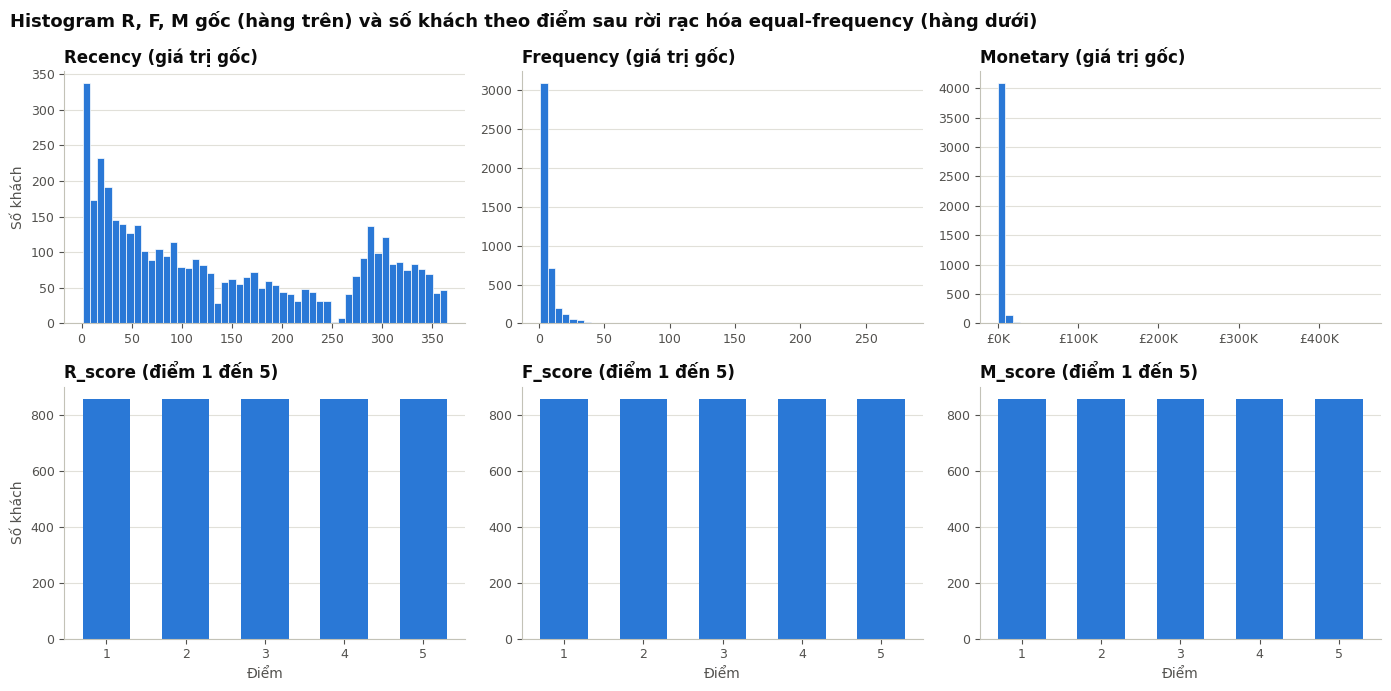

In [6]:
def equal_frequency_score(s, n_bins=5):
    return pd.qcut(s.rank(method="first"), n_bins, labels=False) + 1


rfm["R_score"] = 6 - equal_frequency_score(rfm["Recency"])
rfm["F_score"] = equal_frequency_score(rfm["Frequency"])
rfm["M_score"] = equal_frequency_score(rfm["Monetary"])
X = rfm[SCORE_COLS].to_numpy(dtype=float)

bin_ranges = pd.DataFrame({
    f"{col} ({score})": rfm.groupby(score)[col].agg(lambda s: f"{s.min():,.0f} đến {s.max():,.0f}")
    for col, score in zip(RFM_COLS, SCORE_COLS)
})
bin_ranges.index.name = "Điểm"
bin_ranges["Số khách mỗi thùng"] = rfm["F_score"].value_counts().sort_index()
display(bin_ranges)

fig, axes = plt.subplots(2, 3, figsize=(14, 7))
for j, (col, score) in enumerate(zip(RFM_COLS, SCORE_COLS)):
    axes[0, j].hist(rfm[col], bins=50, color=COLORS[0], edgecolor="white", linewidth=0.5)
    axes[0, j].set_title(f"{col} (giá trị gốc)")
    counts = rfm[score].value_counts().sort_index()
    axes[1, j].bar(counts.index, counts.values, width=0.6, color=COLORS[0])
    axes[1, j].set_title(f"{score} (điểm 1 đến 5)")
    axes[1, j].set_xticks(range(1, 6))
    axes[1, j].set_xlabel("Điểm")
    axes[0, j].set_ylabel("Số khách" if j == 0 else "")
    axes[1, j].set_ylabel("Số khách" if j == 0 else "")
axes[0, 2].xaxis.set_major_formatter(mticker.FuncFormatter(lambda x, _: f"£{x / 1e3:,.0f}K"))
fig.suptitle("Histogram R, F, M gốc (hàng trên) và số khách theo điểm sau rời rạc hóa equal-frequency (hàng dưới)",
             x=0.01, ha="left", fontsize=13, fontweight="bold")
fig.tight_layout()
save_fig(fig, "02_phan_phoi_rfm.png")
plt.show()

**Cách đọc:** bảng cho biết mỗi điểm ứng với khoảng giá trị gốc nào, ví dụ `R_score = 5` là nhóm 20% khách mua gần đây nhất (1 đến 26 ngày). Cột cuối là số khách của mỗi thùng. Hàng trên của biểu đồ là histogram giá trị gốc (C2), hàng dưới là số khách ở mỗi điểm.

**Nhận xét:** - Mỗi thùng có 859 hoặc 860 khách (4.299 không chia hết cho 5), đúng tinh thần equal-frequency. Các thùng có độ rộng rất khác nhau theo giá trị gốc: `M_score = 1` gồm khách chi £3 đến £328, còn `M_score = 5` trải từ £3.070 đến £454.922. Khách chi cực lớn vì vậy chỉ được 5 điểm như mọi khách thuộc 20% chi nhiều nhất.
- Ranh giới Recency: 5 điểm là 1 đến 26 ngày, 4 điểm 26 đến 78 ngày, 3 điểm 78 đến 158 ngày, 2 điểm 158 đến 289 ngày, 1 điểm từ 289 ngày trở lên.
- Với Frequency, toàn bộ thùng 1 và một phần thùng 2 là khách chỉ có 1 hóa đơn; thùng 2 đến thùng 4 cũng chia sẻ giá trị ở ranh giới (3, 5 hóa đơn). Đây chính là các chỗ `rank(method="first")` phải phá hòa.
- Histogram Recency gốc có một **khoảng trống quanh 250 đến 260 ngày**, ứng với khoảng 24/12/2010 đến 04/01/2011, khi cửa hàng nghỉ lễ Giáng sinh. Ngay trước đó (khoảng 280 đến 300 ngày, tức cuối tháng 11/2010) có một "gò" cao: nhiều khách mua lần cuối vào mùa cao điểm 2010 rồi không quay lại.

## 5. Chọn số cụm k (C7)

Thử `k = 2, ..., 10` với K-Means trên ma trận điểm `[R_score, F_score, M_score]` và tính các độ đo sau:

- **Inertia (phương pháp Elbow).** K-Means tìm phân hoạch W và tập tâm cụm Q để cực tiểu hàm mục tiêu (C7):
  P(W, Q) = Σₗ Σᵢ wᵢₗ · d(xᵢ, qₗ), với wᵢₗ = 1 nếu khách i thuộc cụm l, ngược lại bằng 0.
  Khi d là **bình phương khoảng cách Euclid**, P(W, Q) chính là `inertia_` của K-Means. Inertia luôn giảm khi tăng k, nên ta tìm "khuỷu tay": điểm mà sau đó mức giảm chậm lại rõ rệt.
- **Độ chặt** (C7, đánh giá cụm): khoảng cách Euclid trung bình từ mỗi khách tới tâm cụm của mình. Càng nhỏ thì các cụm càng chặt.
- **Độ tách** (C7, đánh giá cụm): khoảng cách Euclid nhỏ nhất giữa hai tâm cụm. Càng lớn thì ngay cả hai cụm gần nhau nhất cũng càng tách biệt.
- **Tỷ số tách/chặt:** gộp hai tiêu chí trên, càng lớn càng tốt.

Hàm `compactness_separation(X, labels)` được dùng chung cho mục này và mục 6. Tâm của mỗi cụm là trung bình các khách trong cụm.

In [7]:
def compactness_separation(X, labels):
    clusters = np.unique(labels)
    centers = np.array([X[labels == c].mean(axis=0) for c in clusters])
    own_center = centers[np.searchsorted(clusters, labels)]
    compactness = np.linalg.norm(X - own_center, axis=1).mean()
    center_dist = np.linalg.norm(centers[:, None, :] - centers[None, :, :], axis=2)
    separation = center_dist[np.triu_indices(len(clusters), k=1)].min() if len(clusters) > 1 else np.nan
    return compactness, separation


k_values = range(2, 11)
rows = []
for k in k_values:
    km = KMeans(n_clusters=k, n_init=10, random_state=RANDOM_STATE).fit(X)
    compactness, separation = compactness_separation(X, km.labels_)
    rows.append({"k": k, "Inertia": km.inertia_, "Độ chặt": compactness, "Độ tách": separation,
                 "Tách/chặt": separation / compactness})
k_scores = pd.DataFrame(rows).set_index("k")
k_scores.insert(1, "Mức giảm inertia so với k - 1", -k_scores["Inertia"].diff())
k_scores.style.format({"Inertia": "{:,.0f}", "Mức giảm inertia so với k - 1": "{:,.0f}", "Độ chặt": "{:.3f}",
                       "Độ tách": "{:.3f}", "Tách/chặt": "{:.2f}"}, na_rep="")

,Inertia,Mức giảm inertia so với k - 1,Độ chặt,Độ tách,Tách/chặt
k,,,,,
2,"11,990",,1.566,3.592,2.29
3,"8,913","3,076",1.359,2.326,1.71
4,"6,407","2,507",1.157,2.469,2.13
5,"5,512",894,1.073,2.124,1.98
6,"4,624",889,0.981,2.128,2.17
7,"4,235",389,0.930,1.627,1.75
8,"3,929",306,0.891,1.385,1.55
9,"3,652",276,0.848,1.548,1.82
10,"3,387",266,0.833,1.272,1.53


Đã lưu: figures/02_chon_so_cum_k.png


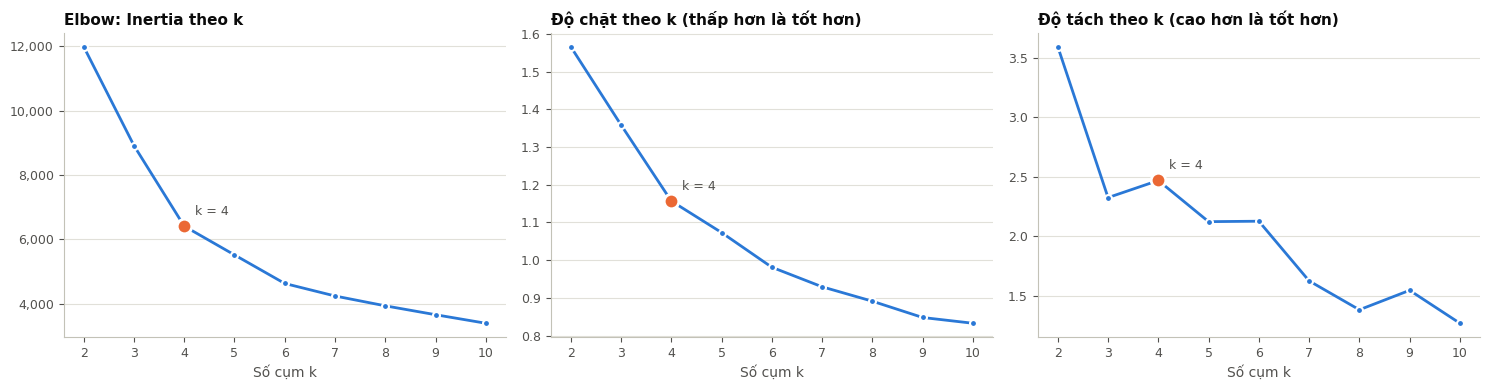

In [8]:
K = 4

fig, axes = plt.subplots(1, 3, figsize=(15, 4))
for ax, col, title in [
    (axes[0], "Inertia", "Elbow: Inertia theo k"),
    (axes[1], "Độ chặt", "Độ chặt theo k (thấp hơn là tốt hơn)"),
    (axes[2], "Độ tách", "Độ tách theo k (cao hơn là tốt hơn)"),
]:
    ax.plot(k_scores.index, k_scores[col], color=COLORS[0], marker="o", markersize=5,
            markeredgecolor="white", markeredgewidth=1.5)
    ax.scatter([K], [k_scores.loc[K, col]], s=110, color=COLORS[1], edgecolor="white", linewidth=2, zorder=3)
    ax.annotate(f"k = {K}", (K, k_scores.loc[K, col]), xytext=(8, 8), textcoords="offset points",
                fontsize=9, color=INK_2)
    ax.set_title(title, fontsize=11)
    ax.set_xlabel("Số cụm k")
    ax.set_xticks(list(k_values))
axes[0].yaxis.set_major_formatter(mticker.FuncFormatter(lambda x, _: f"{x:,.0f}"))
fig.tight_layout()
save_fig(fig, "02_chon_so_cum_k.png")
plt.show()

**Nhận xét và lựa chọn k:** - **Elbow:** inertia giảm 3.076 khi từ k = 2 lên 3 và 2.507 khi từ 3 lên 4, nhưng chỉ giảm 894 khi từ 4 lên 5 (và dưới 900 ở các bước sau). "Khuỷu tay" rõ nhất nằm ở **k = 4**: sau k = 4, thêm cụm gần như không làm các cụm chặt hơn đáng kể.
- **Độ chặt** giảm đều khi tăng k (1,566 ở k = 2 xuống 0,833 ở k = 10), vì càng nhiều cụm thì mỗi khách càng gần tâm cụm của mình. Độ đo này không tự chọn được k mà phải xét cùng độ tách.
- **Độ tách** cao nhất ở k = 2 (3,592); trong các k ≥ 3, **k = 4 có độ tách cao nhất (2,469)**, cao hơn cả k = 3 (2,326). Từ k = 7 trở đi, độ tách giảm mạnh (dưới 1,65): có những cụm nằm sát nhau.
- **Tỷ số tách/chặt** ở k = 4 là 2,13, gần bằng k = 6 (2,17) và chỉ thấp hơn k = 2 (2,29). k = 2 chỉ chia khách thành "tốt" và "kém", quá thô để xây dựng chiến lược riêng; k = 6 không tốt hơn rõ rệt nhưng khó diễn giải hơn.

-> **Chọn k = 4**: điểm gãy Elbow rõ nhất, độ tách cao nhất trong các k ≥ 3, tỷ số tách/chặt cao, và đủ chi tiết để xây dựng chiến lược cho từng nhóm.

## 6. Phân cụm với k = 4 và so sánh với phân cụm phân cấp (C7)

- **K-Means:** gán mỗi khách vào tâm cụm gần nhất rồi cập nhật lại tâm cụm, lặp đến khi hội tụ, để cực tiểu P(W, Q). Các cụm có dạng "hình cầu" quanh tâm.
- **Phân cụm phân cấp gộp** (*agglomerative*): ban đầu mỗi khách là một cụm; mỗi bước gộp hai cụm gần nhau nhất, cho đến khi chỉ còn một cụm. Quá trình gộp được biểu diễn bằng **dendrogram**; cắt dendrogram ở mức thích hợp để được 4 cụm (`fcluster(..., 4, criterion="maxclust")`). Khoảng cách giữa hai cụm phụ thuộc vào **kiểu liên kết**:
  - **single:** khoảng cách nhỏ nhất giữa một đối tượng của cụm này và một đối tượng của cụm kia;
  - **complete:** khoảng cách lớn nhất giữa hai đối tượng thuộc hai cụm;
  - **average:** trung bình khoảng cách của mọi cặp đối tượng thuộc hai cụm;
  - **centroid:** khoảng cách giữa hai tâm cụm.
- Độ đo khoảng cách giữa hai khách: **Euclid**, trên cùng ma trận điểm `X`.

Các phương án được so sánh bằng **kích thước các cụm**, **độ chặt** và **độ tách** (mục 5).

In [9]:
kmeans = KMeans(n_clusters=K, n_init=10, random_state=RANDOM_STATE).fit(X)
labels_kmeans = kmeans.labels_

LINKAGES = ["single", "complete", "average", "centroid"]
linkage_matrices = {method: linkage(X, method=method, metric="euclidean") for method in LINKAGES}
candidates = [("K-Means", labels_kmeans)] + [
    (f"Phân cấp, liên kết {method}", fcluster(Z, K, criterion="maxclust")) for method, Z in linkage_matrices.items()
]

rows = []
for name, labels in candidates:
    compactness, separation = compactness_separation(X, labels)
    rows.append({
        "Thuật toán": name,
        "Số cụm thu được": len(np.unique(labels)),
        "Kích thước các cụm": sorted(np.unique(labels, return_counts=True)[1].tolist(), reverse=True),
        "Độ chặt": compactness,
        "Độ tách": separation,
        "Tách/chặt": separation / compactness,
    })
algo_compare = pd.DataFrame(rows)
print(f"Số điểm khác nhau trong X: {len(np.unique(X, axis=0))} (mỗi khách là một bộ ba điểm 1 đến 5)")
print("Độ cao 5 lần gộp cuối của liên kết single:", np.round(linkage_matrices["single"][-5:, 2], 3).tolist())
algo_compare.style.format({"Độ chặt": "{:.3f}", "Độ tách": "{:.3f}", "Tách/chặt": "{:.2f}"},
                          na_rep="không xác định").hide(axis="index")

Số điểm khác nhau trong X: 110 (mỗi khách là một bộ ba điểm 1 đến 5)
Độ cao 5 lần gộp cuối của liên kết single: [1.0, 1.0, 1.0, 1.0, 1.0]


Thuật toán,Số cụm thu được,Kích thước các cụm,Độ chặt,Độ tách,Tách/chặt
K-Means,4,"[1284, 1121, 947, 947]",1.157,2.469,2.13
"Phân cấp, liên kết single",1,[4299],2.307,không xác định,không xác định
"Phân cấp, liên kết complete",4,"[1472, 1412, 764, 651]",1.272,2.284,1.80
"Phân cấp, liên kết average",4,"[2838, 1458, 2, 1]",1.621,3.412,2.11
"Phân cấp, liên kết centroid",4,"[2963, 1334, 1, 1]",1.643,3.394,2.07


Đã lưu: figures/02_dendrogram.png


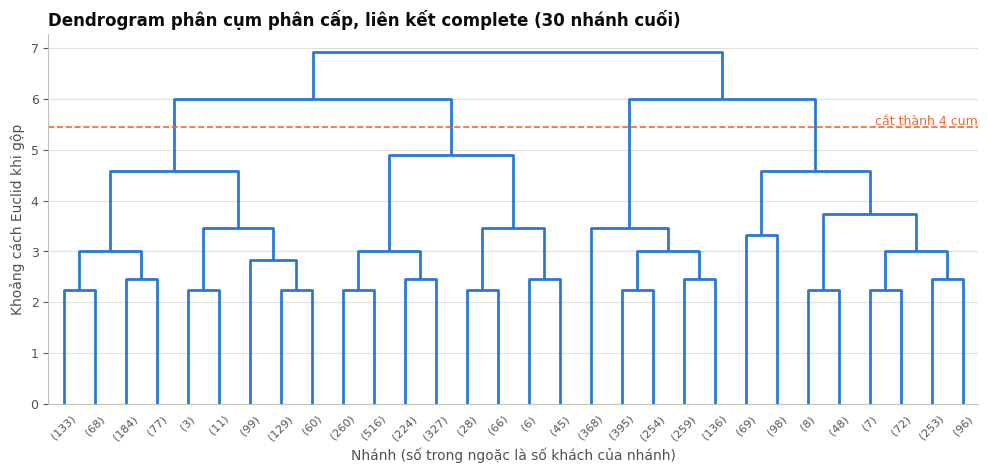

In [10]:
Z_complete = linkage_matrices["complete"]
cut_height = (Z_complete[-K, 2] + Z_complete[-(K - 1), 2]) / 2

fig, ax = plt.subplots(figsize=(12, 4.8))
dendrogram(Z_complete, truncate_mode="lastp", p=30, ax=ax, color_threshold=0,
           above_threshold_color=COLORS[0], leaf_font_size=8)
ax.axhline(cut_height, color=COLORS[1], linewidth=1.2, linestyle="--")
ax.text(ax.get_xlim()[1], cut_height, f" cắt thành {K} cụm", va="bottom", ha="right", fontsize=9, color=COLORS[1])
ax.set_title("Dendrogram phân cụm phân cấp, liên kết complete (30 nhánh cuối)")
ax.set_xlabel("Nhánh (số trong ngoặc là số khách của nhánh)")
ax.set_ylabel("Khoảng cách Euclid khi gộp")
ax.grid(axis="x", visible=False)
save_fig(fig, "02_dendrogram.png")
plt.show()

**Cách đọc:** mỗi dòng của bảng là một phương án phân 4 cụm. Trên dendrogram, mỗi lần hai nhánh nối với nhau là một lần gộp hai cụm, độ cao của chỗ nối là khoảng cách giữa hai cụm theo liên kết complete; đường nét đứt là mức cắt để còn 4 cụm.

**Nhận xét:** - Ma trận `X` chỉ có **110 điểm khác nhau** (mỗi khách là một bộ ba điểm nguyên 1 đến 5), xếp thành một lưới với bước 1.
- **Liên kết single** gặp hiện tượng "chuỗi dài" (*chaining*) ở mức cực đoan: hai điểm kề nhau trên lưới luôn cách nhau đúng 1, nên mọi lần gộp, kể cả lần cuối, đều ở khoảng cách 1. Không có mức cắt nào tách được dữ liệu, `fcluster` chỉ trả về **1 cụm** gồm cả 4.299 khách.
- **Liên kết average và centroid** cũng tạo ra cụm chỉ có 1 đến 2 khách (kích thước [2.838, 1.458, 2, 1] và [2.963, 1.334, 1, 1]): thực chất chỉ là 2 cụm lớn cộng vài điểm ở góc lưới. Độ tách của hai phương án này cao (3,41 và 3,39) chỉ vì các cụm tí hon nằm xa phần còn lại, nhưng độ chặt kém nhất (1,62 và 1,64). Các phương án này không dùng được cho phân khúc.
- **Liên kết complete** tạo các cụm gọn, kích thước cân đối ([1.472, 1.412, 764, 651]), đúng như đặc điểm nêu trong slide. Dendrogram cho thấy 4 nhánh lớn tách nhau rõ ở độ cao khoảng 5,5 đến 6.
- **K-Means tốt hơn complete ở cả hai tiêu chí:** độ chặt 1,157 so với 1,272 và độ tách 2,469 so với 2,284. Kết hợp với ưu điểm đơn giản và dễ giải thích, ta **chọn K-Means** làm kết quả phân cụm chính.

## 7. Mô tả và đặt tên cụm

Số thứ tự cụm do K-Means sinh ra là ngẫu nhiên, nên trước hết xem giá trị RFM trung bình theo nhãn gốc của K-Means.

In [11]:
rfm["KMeansLabel"] = labels_kmeans
rfm.groupby("KMeansLabel")[RFM_COLS + SCORE_COLS + ["Tenure", "churn"]].mean().assign(
    NumCustomers=rfm["KMeansLabel"].value_counts().sort_index())

,Recency,Frequency,Monetary,R_score,F_score,M_score,Tenure,churn,NumCustomers
KMeansLabel,,,,,,,,,
0,277.60,1.61,413.46,1.45,1.62,1.66,351.36,0.74,1121
1,205.83,5.50,"2,108.40",2.12,3.55,3.61,516.76,0.53,947
2,66.63,2.10,534.91,3.87,1.99,1.93,210.75,0.54,947
3,37.70,14.87,"7,604.91",4.37,4.55,4.51,528.56,0.21,1284


Dựa vào bảng trên, ta đặt tên cụm theo các quy tắc sau, tính trên **giá trị gốc** trung bình của R, F, M trong mỗi cụm (viết thành code để kết quả không phụ thuộc vào thứ tự nhãn ngẫu nhiên của K-Means):

1. Cụm có **Frequency trung bình cao nhất** -> **VIP** (mua thường xuyên, chi tiêu nhiều, mới mua gần đây).
2. Trong các cụm còn lại, cụm có **Recency thấp nhất** (mới mua gần đây) -> **Khách mới** (mua gần đây nhưng ít lần, thâm niên ngắn).
3. Trong hai cụm còn lại, cụm có **Frequency cao hơn** -> **Có nguy cơ** (từng mua khá đều nhưng đã lâu không quay lại).
4. Cụm cuối cùng -> **Ngủ đông** (mua rất ít, đã lâu không quay lại).

Sau đó đánh số lại `Cluster` theo thứ tự 0 = VIP, 1 = Khách mới, 2 = Có nguy cơ, 3 = Ngủ đông. Thứ tự này đi từ nhóm giá trị cao nhất đến thấp nhất.

In [12]:
profile_raw = rfm.groupby("KMeansLabel")[RFM_COLS].mean()

vip = profile_raw["Frequency"].idxmax()
remaining = profile_raw.drop(index=vip)
new = remaining["Recency"].idxmin()
remaining = remaining.drop(index=new)
at_risk = remaining["Frequency"].idxmax()
dormant = remaining["Frequency"].idxmin()

label_to_cluster = {int(vip): 0, int(new): 1, int(at_risk): 2, int(dormant): 3}
CLUSTER_NAMES = {0: "VIP", 1: "Khách mới", 2: "Có nguy cơ", 3: "Ngủ đông"}
CLUSTER_ORDER = list(CLUSTER_NAMES.values())
CLUSTER_COLORS = dict(zip(CLUSTER_ORDER, COLORS[:4]))

rfm["Cluster"] = rfm["KMeansLabel"].map(label_to_cluster)
rfm["ClusterName"] = rfm["Cluster"].map(CLUSTER_NAMES)
print("Nhãn K-Means -> Cluster mới:", label_to_cluster)

Nhãn K-Means -> Cluster mới: {3: 0, 2: 1, 1: 2, 0: 3}


In [13]:
total_revenue = rfm["Monetary"].sum()
cluster_profile = rfm.groupby("ClusterName").agg(
    NumCustomers=("Recency", "size"),
    Recency_mean=("Recency", "mean"),
    Recency_median=("Recency", "median"),
    Frequency_mean=("Frequency", "mean"),
    Frequency_median=("Frequency", "median"),
    Monetary_mean=("Monetary", "mean"),
    Monetary_median=("Monetary", "median"),
    Monetary_sum=("Monetary", "sum"),
    Tenure_mean=("Tenure", "mean"),
    ChurnRate=("churn", "mean"),
).reindex(CLUSTER_ORDER)
cluster_profile["CustomerShare"] = cluster_profile["NumCustomers"] / len(rfm) * 100
cluster_profile["RevenueShare"] = cluster_profile["Monetary_sum"] / total_revenue * 100
cluster_profile["ChurnRate"] = cluster_profile["ChurnRate"] * 100

profile_table = cluster_profile[[
    "NumCustomers", "CustomerShare", "Recency_mean", "Frequency_mean", "Monetary_mean",
    "Monetary_median", "Tenure_mean", "RevenueShare", "ChurnRate",
]].rename(columns={
    "NumCustomers": "Số khách", "CustomerShare": "% khách", "Recency_mean": "Recency TB (ngày)",
    "Frequency_mean": "Frequency TB", "Monetary_mean": "Monetary TB (£)", "Monetary_median": "Monetary trung vị (£)",
    "Tenure_mean": "Thâm niên TB (ngày)", "RevenueShare": "% doanh thu", "ChurnRate": "Tỷ lệ churn (%)",
})
profile_table.style.format({
    "Số khách": "{:,.0f}", "% khách": "{:.1f}", "Recency TB (ngày)": "{:.1f}", "Frequency TB": "{:.1f}",
    "Monetary TB (£)": "{:,.0f}", "Monetary trung vị (£)": "{:,.0f}", "Thâm niên TB (ngày)": "{:,.0f}",
    "% doanh thu": "{:.1f}", "Tỷ lệ churn (%)": "{:.1f}",
})

,Số khách,% khách,Recency TB (ngày),Frequency TB,Monetary TB (£),Monetary trung vị (£),Thâm niên TB (ngày),% doanh thu,Tỷ lệ churn (%)
ClusterName,,,,,,,,,
VIP,"1,284",29.9,37.7,14.9,"7,605","3,598",529,76.7,21.3
Khách mới,947,22.0,66.6,2.1,535,451,211,4.0,53.9
Có nguy cơ,947,22.0,205.8,5.5,"2,108","1,433",517,15.7,52.8
Ngủ đông,"1,121",26.1,277.6,1.6,413,344,351,3.6,74.2


**Kiểm tra tên cụm:** quy tắc đặt tên vẫn cho ra đúng 4 nhóm có ý nghĩa. VIP có Frequency trung bình cao nhất (14,9) và cả 3 điểm đều trên 4,3. Trong 3 cụm còn lại, cụm mua gần đây nhất (Recency TB 67 ngày) cũng là cụm có thâm niên ngắn nhất (211 ngày), nên tên **Khách mới** hợp lý. Cụm **Có nguy cơ** từng mua khá nhiều (5,5 hóa đơn) nhưng đã gần 7 tháng không quay lại; cụm **Ngủ đông** vừa mua ít vừa đã lâu không mua.

**Mô tả các cụm:**

| Cụm | Đặc điểm chính | Ý nghĩa |
|---|---|---|
| **VIP** (1.284 khách, 30%) | Mua gần đây (Recency TB 38 ngày), thường xuyên (TB 14,9 hóa đơn), chi tiêu cao (TB £7.605, trung vị £3.598), thâm niên lâu (TB 529 ngày) | Chiếm 30% số khách nhưng đóng góp **77% doanh thu**. Tỷ lệ churn thấp nhất (21%) |
| **Khách mới** (947 khách, 22%) | Mua tương đối gần đây (Recency TB 67 ngày) nhưng ít lần (TB 2,1 hóa đơn), chi tiêu thấp (TB £535), thâm niên ngắn nhất (TB 211 ngày, khoảng 7 tháng) | Khách mới bắt đầu quan hệ với cửa hàng, chỉ 4% doanh thu. Churn 54%: hơn một nửa không quay lại, đây là giai đoạn quyết định để giữ chân |
| **Có nguy cơ** (947 khách, 22%) | Từng mua khá đều (TB 5,5 hóa đơn, £2.108, thâm niên 517 ngày) nhưng đã lâu không quay lại (Recency TB 206 ngày, gần 7 tháng) | Đóng góp 16% doanh thu, lớn thứ hai. Churn 53%. Nhóm **đáng cứu nhất** sau VIP vì có giá trị lịch sử khá |
| **Ngủ đông** (1.121 khách, 26%) | Mua 1 đến 2 lần (TB 1,6 hóa đơn), chi ít (TB £413), lần mua cuối đã khoảng 9 tháng (Recency TB 278 ngày) | Chỉ 4% doanh thu, churn cao nhất (74%) |

## 8. Trực quan hóa và diễn giải các cụm (C7)

Theo C7, mỗi cụm được diễn giải bằng **trung bình cụm** (mục 8.1), **phân phối** của các thuộc tính trong cụm (mục 8.2, 8.3) và **cây quyết định** chạy trên dữ liệu đã phân cụm (mục 8.5).

### 8.1. Điểm R, F, M trung bình theo cụm

Biểu đồ vẽ điểm trung bình (thang 1 đến 5) của R_score, F_score, M_score cho từng cụm. Với cả ba điểm, **cao là tốt**; mức 3 là trung bình của toàn bộ khách (vì mỗi điểm có đúng 20% khách).

Đã lưu: figures/02_snake_plot.png


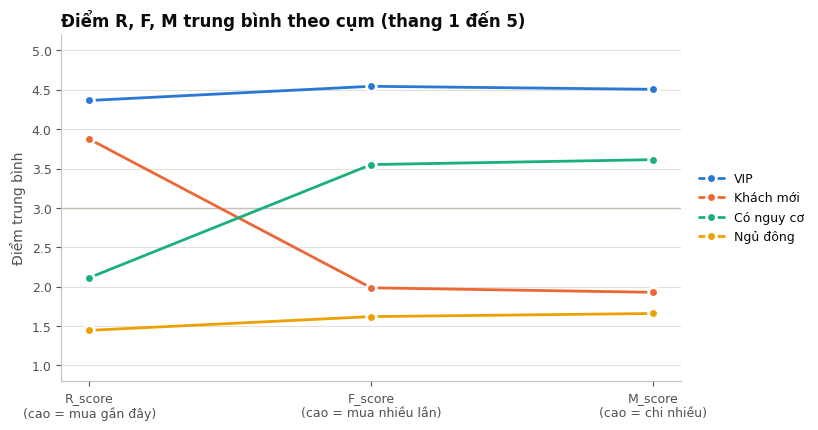

,R_score,F_score,M_score
ClusterName,,,
VIP,4.37,4.55,4.51
Khách mới,3.87,1.99,1.93
Có nguy cơ,2.12,3.55,3.61
Ngủ đông,1.45,1.62,1.66


In [14]:
score_profile = rfm.groupby("ClusterName")[SCORE_COLS].mean().reindex(CLUSTER_ORDER)

fig, ax = plt.subplots(figsize=(8, 4.5))
ax.axhline(3, color="#c3c2b7", linewidth=1)
for name in CLUSTER_ORDER:
    ax.plot(SCORE_COLS, score_profile.loc[name], color=CLUSTER_COLORS[name], marker="o", markersize=7,
            markeredgecolor="white", markeredgewidth=2, label=name)
ax.set_title("Điểm R, F, M trung bình theo cụm (thang 1 đến 5)")
ax.set_ylabel("Điểm trung bình")
ax.set_ylim(0.8, 5.2)
ax.set_xticks(range(3), ["R_score\n(cao = mua gần đây)", "F_score\n(cao = mua nhiều lần)", "M_score\n(cao = chi nhiều)"])
ax.legend(loc="center left", bbox_to_anchor=(1.01, 0.5))
save_fig(fig, "02_snake_plot.png")
plt.show()
score_profile

**Nhận xét:** - **VIP** cao trên cả ba điểm (R 4,4; F 4,6; M 4,5). **Ngủ đông** thấp trên cả ba (1,5; 1,6; 1,7).
- **Khách mới** và **Có nguy cơ** là hai hình ảnh "ngược nhau": Khách mới có R cao (3,9) nhưng F, M thấp (khoảng 2); Có nguy cơ có F, M khá (khoảng 3,6) nhưng R thấp (2,1). Hai đường cắt nhau giữa R_score và F_score cho thấy K-Means đã tách được hai kiểu khách khác hẳn nhau dù có tỷ lệ churn gần bằng nhau.

### 8.2. Boxplot R, F, M theo cụm

Boxplot (C1, C2) cho thấy trung vị, tứ phân vị và độ phân tán của giá trị gốc trong mỗi cụm. Frequency và Monetary được vẽ với **trục tung theo thang log**; đây chỉ là cách hiển thị để thấy rõ cả các cụm có giá trị nhỏ, dữ liệu không bị biến đổi.

Đã lưu: figures/02_boxplot_rfm_theo_cum.png


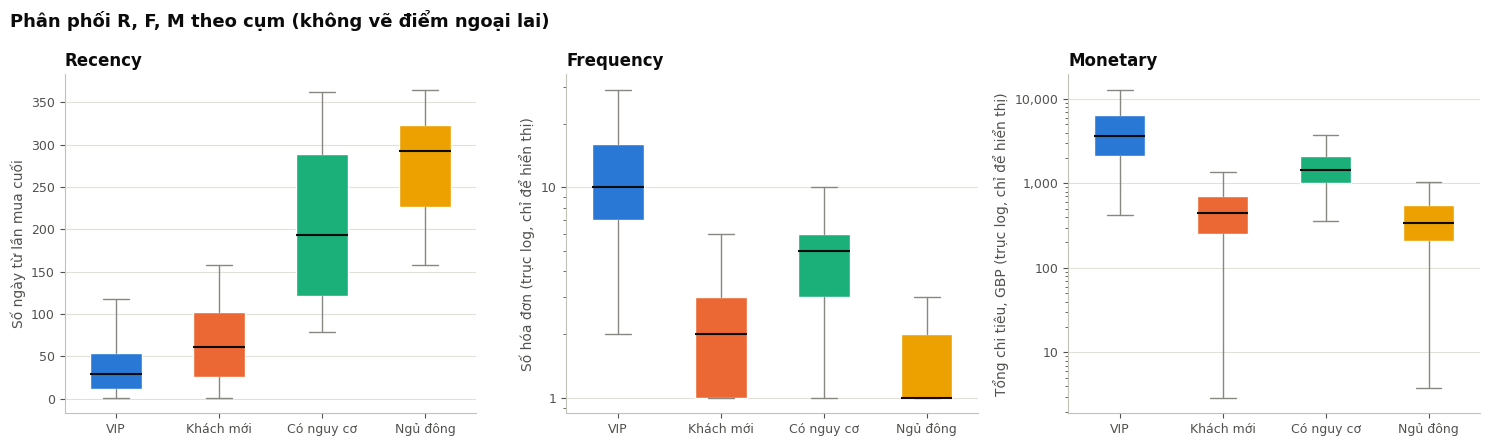

In [15]:
fig, axes = plt.subplots(1, 3, figsize=(15, 4.5))
for ax, col, ylabel in [
    (axes[0], "Recency", "Số ngày từ lần mua cuối"),
    (axes[1], "Frequency", "Số hóa đơn (trục log, chỉ để hiển thị)"),
    (axes[2], "Monetary", "Tổng chi tiêu, GBP (trục log, chỉ để hiển thị)"),
]:
    data = [rfm.loc[rfm["ClusterName"] == name, col] for name in CLUSTER_ORDER]
    box = ax.boxplot(data, patch_artist=True, widths=0.5, showfliers=False,
                     medianprops=dict(color=INK, linewidth=1.5),
                     whiskerprops=dict(color=MUTED), capprops=dict(color=MUTED))
    for patch, name in zip(box["boxes"], CLUSTER_ORDER):
        patch.set_facecolor(CLUSTER_COLORS[name])
        patch.set_edgecolor("white")
    ax.set_xticks(range(1, K + 1), CLUSTER_ORDER)
    ax.set_title(col)
    ax.set_ylabel(ylabel)
    if col != "Recency":
        ax.set_yscale("log")
        ax.yaxis.set_major_formatter(mticker.FuncFormatter(lambda x, _: f"{x:,.0f}"))
fig.suptitle("Phân phối R, F, M theo cụm (không vẽ điểm ngoại lai)", x=0.01, ha="left",
             fontsize=13, fontweight="bold")
fig.tight_layout()
save_fig(fig, "02_boxplot_rfm_theo_cum.png")
plt.show()

**Nhận xét:** - **Recency** tách các cụm thành hai nhóm: VIP và Khách mới mua gần đây (trung vị dưới 2 tháng), Có nguy cơ và Ngủ đông đã lâu không mua (trung vị khoảng 190 và 290 ngày). Hộp Recency của Có nguy cơ trải rộng nhất (khoảng 120 đến 290 ngày).
- **Frequency** và **Monetary** tách theo chiều còn lại: VIP cao nhất (trung vị khoảng 10 hóa đơn và £3.600), Có nguy cơ đứng thứ hai, Khách mới và Ngủ đông chỉ 1 đến 3 hóa đơn và vài trăm bảng.
- Như vậy mỗi cụm khác các cụm còn lại ít nhất ở một chiều: Khách mới khác Ngủ đông ở Recency, Có nguy cơ khác Ngủ đông ở Frequency và Monetary, VIP khác Khách mới ở Frequency và Monetary.

### 8.3. Scatter plot Recency và Frequency (C2)

Scatter plot của hai thuộc tính gốc: trục hoành là Recency, trục tung là Frequency. Trục tung được cắt ở phân vị 99% của Frequency để vài khách mua hàng trăm lần không làm dồn phần còn lại xuống đáy; những khách này vẫn được tính khi xác định tâm cụm. Để dễ nhìn, mỗi ô làm nổi bật một cụm, các cụm khác tô xám; chấm đen là trung bình (Recency, Frequency) của cụm.

Phân vị 99% của Frequency: 46 hóa đơn; 41 khách vượt ngưỡng không được vẽ


Đã lưu: figures/02_scatter_rf.png


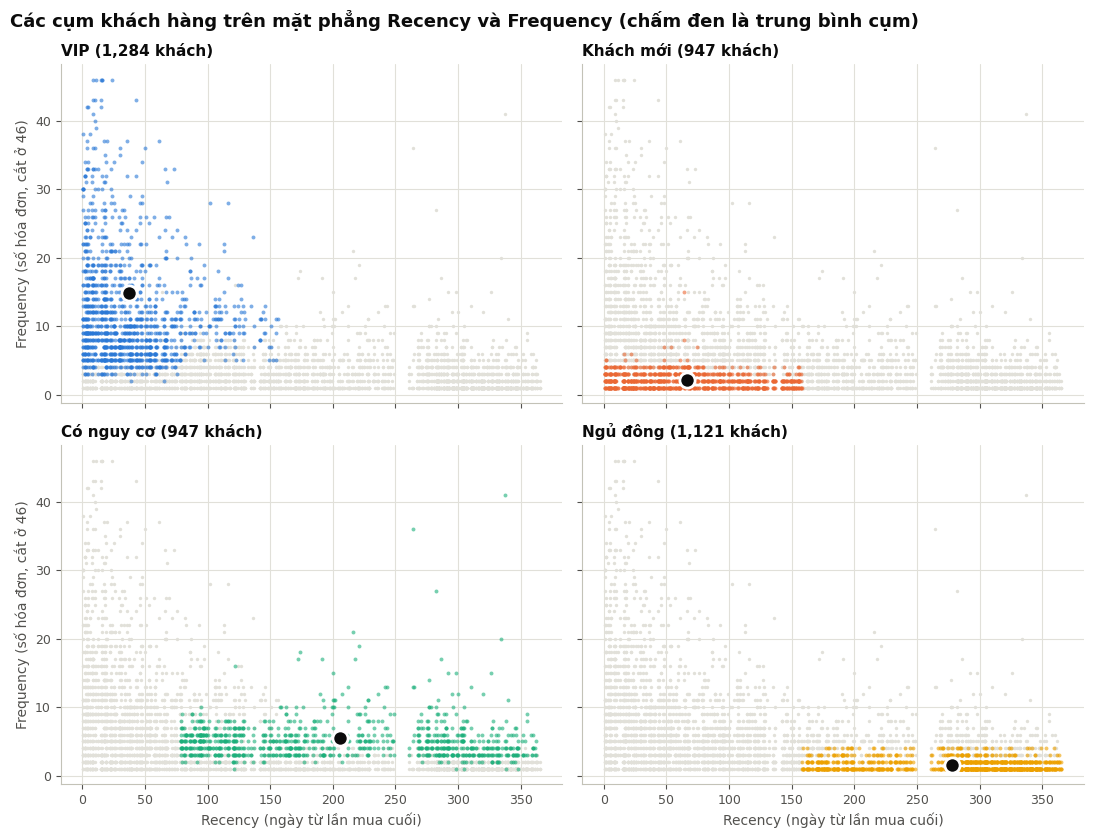

In [16]:
f_cap = rfm["Frequency"].quantile(0.99)
shown = rfm[rfm["Frequency"] <= f_cap]
print(f"Phân vị 99% của Frequency: {f_cap:.0f} hóa đơn; {len(rfm) - len(shown)} khách vượt ngưỡng không được vẽ")

fig, axes = plt.subplots(2, 2, figsize=(11, 8.5), sharex=True, sharey=True)
for ax, name in zip(axes.ravel(), CLUSTER_ORDER):
    mask = shown["ClusterName"] == name
    ax.scatter(shown.loc[~mask, "Recency"], shown.loc[~mask, "Frequency"], s=6, color=GRID, linewidths=0)
    ax.scatter(shown.loc[mask, "Recency"], shown.loc[mask, "Frequency"], s=8, color=CLUSTER_COLORS[name],
               linewidths=0, alpha=0.6)
    center = rfm.loc[rfm["ClusterName"] == name, ["Recency", "Frequency"]].mean()
    ax.scatter(center["Recency"], center["Frequency"], s=120, color=INK, edgecolor="white", linewidth=2, zorder=3)
    ax.set_title(f"{name} ({(rfm['ClusterName'] == name).sum():,} khách)", fontsize=11)
    ax.grid(axis="x", visible=True)
for ax in axes[1]:
    ax.set_xlabel("Recency (ngày từ lần mua cuối)")
for ax in axes[:, 0]:
    ax.set_ylabel(f"Frequency (số hóa đơn, cắt ở {f_cap:.0f})")
fig.suptitle("Các cụm khách hàng trên mặt phẳng Recency và Frequency (chấm đen là trung bình cụm)", x=0.01,
             ha="left", fontsize=13, fontweight="bold")
fig.tight_layout()
save_fig(fig, "02_scatter_rf.png")
plt.show()

**Nhận xét:** - Các cụm chiếm những vùng gần như không chồng nhau trên mặt phẳng Recency và Frequency: VIP ở góc trên bên trái (mua gần đây, nhiều lần), Khách mới ở dải dưới bên trái (Recency đến khoảng 158 ngày, Frequency 1 đến 5), Ngủ đông ở dải dưới bên phải (Recency từ khoảng 158 ngày, Frequency 1 đến 4), còn Có nguy cơ ở vùng giữa bên phải (Recency từ khoảng 80 ngày, Frequency 3 đến 10).
- Ranh giới giữa các cụm là các đường thẳng đứng hoặc nằm ngang, trùng với ranh giới của các thùng điểm (ví dụ Recency 78 và 158 ngày). Đây là hệ quả trực tiếp của việc phân cụm trên điểm rời rạc.
- Các cụm nằm sát nhau, không có khoảng trống rõ rệt giữa chúng: K-Means đang chia một "đám mây" khách hàng liên tục thành những vùng có ý nghĩa kinh doanh, chứ không tìm ra các nhóm tách biệt tự nhiên. Khoảng trống dọc quanh Recency 250 đến 260 ngày là kỳ nghỉ Giáng sinh 2010 (mục 4), không phải ranh giới cụm.

### 8.4. Tỷ trọng khách hàng, doanh thu và tỷ lệ churn theo cụm

Đã lưu: figures/02_ty_trong_va_churn_theo_cum.png


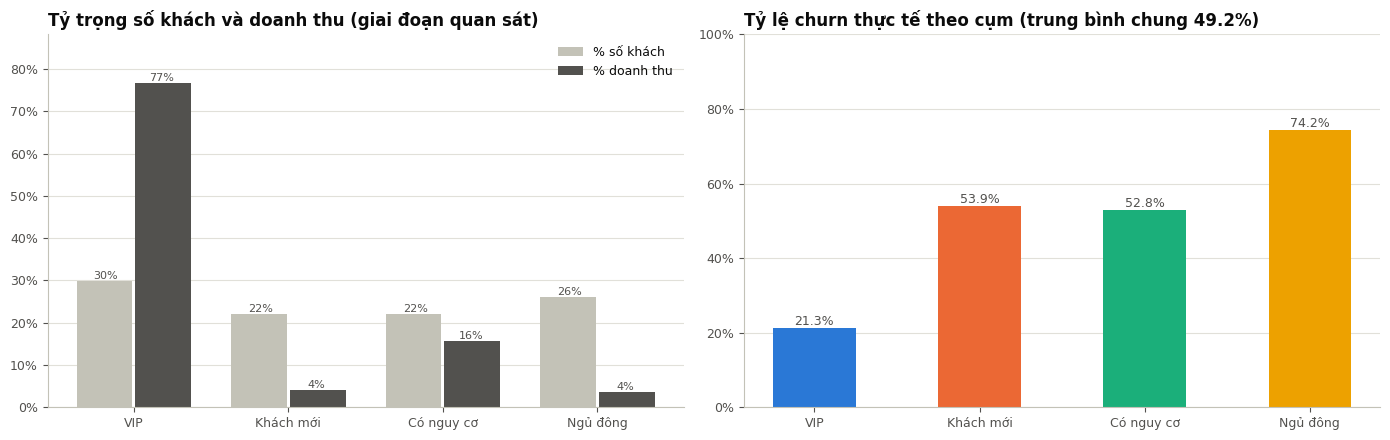

In [17]:
fig, axes = plt.subplots(1, 2, figsize=(14, 4.5))

x = np.arange(K)
w = 0.36
ax = axes[0]
ax.bar(x - w / 2 - 0.01, cluster_profile["CustomerShare"], width=w, color="#c3c2b7", label="% số khách")
ax.bar(x + w / 2 + 0.01, cluster_profile["RevenueShare"], width=w, color=INK_2, label="% doanh thu")
for i in range(K):
    ax.text(x[i] - w / 2, cluster_profile["CustomerShare"].iloc[i], f"{cluster_profile['CustomerShare'].iloc[i]:.0f}%",
            ha="center", va="bottom", fontsize=8, color=INK_2)
    ax.text(x[i] + w / 2, cluster_profile["RevenueShare"].iloc[i], f"{cluster_profile['RevenueShare'].iloc[i]:.0f}%",
            ha="center", va="bottom", fontsize=8, color=INK_2)
ax.set_xticks(x, CLUSTER_ORDER)
ax.yaxis.set_major_formatter(mticker.PercentFormatter())
ax.set_ylim(0, cluster_profile[["CustomerShare", "RevenueShare"]].max().max() * 1.15)
ax.set_title("Tỷ trọng số khách và doanh thu (giai đoạn quan sát)")
ax.legend(loc="upper right")

ax = axes[1]
overall_churn = rfm["churn"].mean() * 100
ax.bar(x, cluster_profile["ChurnRate"], width=0.5, color=[CLUSTER_COLORS[n] for n in CLUSTER_ORDER])
for i, v in enumerate(cluster_profile["ChurnRate"]):
    ax.text(i, v, f"{v:.1f}%", ha="center", va="bottom", fontsize=9, color=INK_2)
ax.set_xticks(x, CLUSTER_ORDER)
ax.yaxis.set_major_formatter(mticker.PercentFormatter())
ax.set_ylim(0, 100)
ax.set_title(f"Tỷ lệ churn thực tế theo cụm (trung bình chung {overall_churn:.1f}%)")
fig.tight_layout()
save_fig(fig, "02_ty_trong_va_churn_theo_cum.png")
plt.show()

**Nhận xét:** - **Doanh thu tập trung rất mạnh**: VIP chiếm 30% số khách nhưng mang lại 77% doanh thu. Một khách VIP trung bình chi tiêu gấp khoảng 18 lần một khách Ngủ đông (£7.605 so với £413). Giữ chân VIP vì thế là ưu tiên số một về giá trị.
- **Tỷ lệ churn** thấp nhất ở VIP (21,3%), cao nhất ở Ngủ đông (74,2%); hai cụm ở giữa gần như bằng nhau: Có nguy cơ 52,8% và Khách mới 53,9%. Dù thuật toán phân cụm không hề dùng nhãn churn, các cụm RFM đã chứa nhiều thông tin về nguy cơ rời bỏ. Đây là cơ sở để đưa nhãn cụm làm đặc trưng cho mô hình dự đoán ở notebook 03.
- Tuy vậy, ngay cả VIP vẫn có 21% rời bỏ, còn 26% khách Ngủ đông vẫn quay lại mua. Cụm chỉ cho biết nguy cơ **trung bình của nhóm**; để biết khách cụ thể nào sắp rời bỏ, cần mô hình dự đoán ở mức từng khách hàng.

### 8.5. Mô tả cụm bằng cây quyết định (C7)

Theo slide C7 (*Use Decision Tree to Find Description of Clusters*), sau khi phân cụm có thể dùng **nhãn cụm làm thuộc tính lớp** và huấn luyện một cây quyết định trên dữ liệu đã phân cụm. Mỗi đường đi từ gốc đến lá là một luật "nếu ... thì thuộc cụm ...", mô tả cụm bằng ngưỡng trên **giá trị gốc**, dễ hiểu hơn điểm 1 đến 5.

- Đầu vào: Recency, Frequency, Monetary (giá trị gốc); nhãn: `ClusterName`.
- `max_depth=3`: mỗi luật có tối đa 3 điều kiện, đủ ngắn để trình bày.
- Tiêu chí tách mặc định là chỉ số Gini (CART, C4).

Mỗi ô trong hình ghi: điều kiện tách, `samples` = số khách rơi vào ô, `value` = số khách của từng cụm theo thứ tự `Có nguy cơ, Khách mới, Ngủ đông, VIP`, `class` = cụm chiếm đa số (ô được tô theo màu của cụm đó).

Tỷ lệ khách được cây xếp đúng cụm: 91.3%
Theo từng cụm: {'VIP': '88.4%', 'Khách mới': '95.9%', 'Có nguy cơ': '81.0%', 'Ngủ đông': '99.3%'}


Đã lưu: figures/02_cay_mo_ta_cum.png


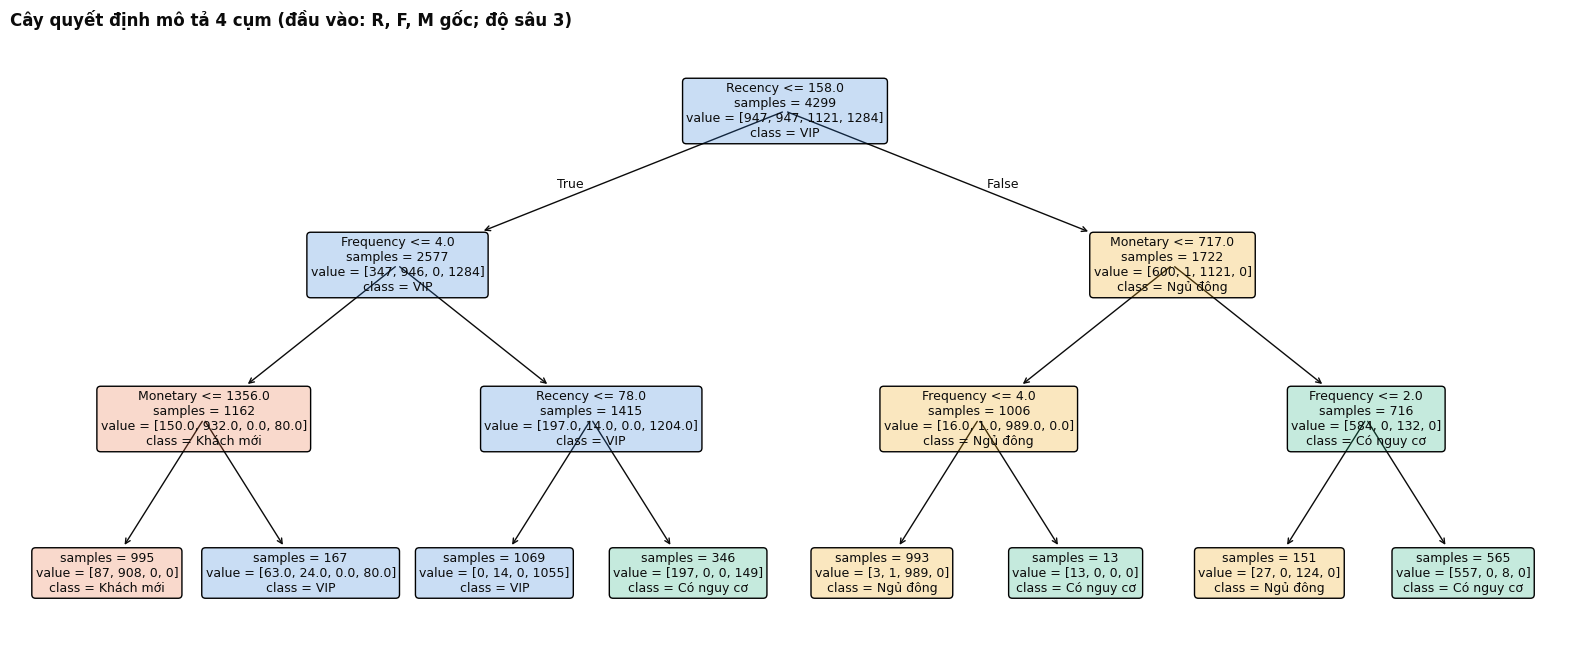

|--- Recency <= 158
|   |--- Frequency <= 4
|   |   |--- Monetary <= 1356
|   |   |   |--- weights: [87, 908, 0, 0] class: Khách mới
|   |   |--- Monetary >  1356
|   |   |   |--- weights: [63, 24, 0, 80] class: VIP
|   |--- Frequency >  4
|   |   |--- Recency <= 78
|   |   |   |--- weights: [0, 14, 0, 1055] class: VIP
|   |   |--- Recency >  78
|   |   |   |--- weights: [197, 0, 0, 149] class: Có nguy cơ
|--- Recency >  158
|   |--- Monetary <= 717
|   |   |--- Frequency <= 4
|   |   |   |--- weights: [3, 1, 989, 0] class: Ngủ đông
|   |   |--- Frequency >  4
|   |   |   |--- weights: [13, 0, 0, 0] class: Có nguy cơ
|   |--- Monetary >  717
|   |   |--- Frequency <= 2
|   |   |   |--- weights: [27, 0, 124, 0] class: Ngủ đông
|   |   |--- Frequency >  2
|   |   |   |--- weights: [557, 0, 8, 0] class: Có nguy cơ



In [18]:
desc_tree = DecisionTreeClassifier(max_depth=3, random_state=RANDOM_STATE)
desc_tree.fit(rfm[RFM_COLS], rfm["ClusterName"])
tree_pred = desc_tree.predict(rfm[RFM_COLS])
print(f"Tỷ lệ khách được cây xếp đúng cụm: {(tree_pred == rfm['ClusterName']).mean():.1%}")
print("Theo từng cụm:", {name: f"{acc:.1%}" for name, acc in
                         (tree_pred == rfm["ClusterName"]).groupby(rfm["ClusterName"]).mean().reindex(CLUSTER_ORDER).items()})

fig, ax = plt.subplots(figsize=(20, 8))
annotations = plot_tree(desc_tree, feature_names=RFM_COLS, class_names=desc_tree.classes_.tolist(),
                        filled=False, rounded=True, impurity=False, precision=0, fontsize=9, ax=ax)
node_boxes = [annotation.get_bbox_patch() for annotation in annotations if annotation.get_bbox_patch() is not None]
for node_id, box in enumerate(node_boxes):
    node_class = desc_tree.classes_[desc_tree.tree_.value[node_id][0].argmax()]
    box.set_facecolor(to_rgba(CLUSTER_COLORS[node_class], 0.25))
ax.set_title("Cây quyết định mô tả 4 cụm (đầu vào: R, F, M gốc; độ sâu 3)")
save_fig(fig, "02_cay_mo_ta_cum.png")
plt.show()

print(export_text(desc_tree, feature_names=RFM_COLS, show_weights=True, decimals=0))

**Cách đọc tập luật:** mỗi dòng `|---` là một điều kiện, thụt lề càng sâu thì càng xa gốc. Dòng `class` là lá: `weights` là số khách của từng cụm (theo thứ tự `Có nguy cơ, Khách mới, Ngủ đông, VIP`) rơi vào lá đó, và lá được gán cho cụm chiếm đa số.

**Nhận xét:** - Chỉ với 3 tầng điều kiện trên giá trị gốc, cây xếp đúng cụm cho **91,3% khách** (Ngủ đông 99,3%, Khách mới 95,9%, VIP 88,4%, Có nguy cơ 81,0%). Các cụm K-Means vì vậy mô tả được bằng vài luật đơn giản:
  - **VIP:** Recency ≤ 78 ngày **và** Frequency > 4 hóa đơn (1.055 trên 1.069 khách của lá là VIP).
  - **Khách mới:** Recency ≤ 158 ngày, Frequency ≤ 4 **và** Monetary ≤ £1.356 (908 trên 995 khách).
  - **Ngủ đông:** Recency > 158 ngày, Monetary ≤ £717 **và** Frequency ≤ 4 (989 trên 993 khách).
  - **Có nguy cơ:** Recency > 158 ngày, Monetary > £717 **và** Frequency > 2 (557 trên 565 khách).
- Điều kiện đầu tiên là **Recency ≤ 158 ngày** (khoảng 5 tháng), chia khách thành nhóm "còn mua" (VIP, Khách mới) và nhóm "đã lâu không mua" (Có nguy cơ, Ngủ đông). Các ngưỡng 78 và 158 ngày, £717 trùng với ranh giới các thùng điểm ở mục 4.
- Hai lá còn lẫn: khách mua gần đây, ít lần nhưng chi nhiều (Monetary > £1.356) chia giữa VIP, Có nguy cơ và Khách mới; khách có Recency 79 đến 158 ngày và trên 4 hóa đơn chia giữa Có nguy cơ (197) và VIP (149). Đây là vùng giáp ranh giữa các cụm, nơi K-Means phân chia theo tổng hợp cả ba điểm chứ không theo một ngưỡng đơn lẻ.

## 9. Xuất dữ liệu

File được ghi với mã hóa `utf-8-sig` để tên cụm tiếng Việt hiển thị đúng khi mở bằng Excel.

In [19]:
customers_clustered = rfm.reset_index()[["CustomerID", "Recency", "Frequency", "Monetary", "R_score", "F_score",
                                         "M_score", "Cluster", "ClusterName", "churn"]]
customers_clustered.to_csv(PROCESSED_DIR / "customers_clustered.csv", index=False, encoding="utf-8-sig")
print(customers_clustered.shape)
customers_clustered.head()

(4299, 10)


,CustomerID,Recency,Frequency,Monetary,R_score,F_score,M_score,Cluster,ClusterName,churn
0,12347,39,6,"3,402.39",4,4,5,0,VIP,0
1,12348,158,4,"1,388.40",3,3,4,2,Có nguy cơ,0
2,12349,317,2,"2,221.14",1,2,4,2,Có nguy cơ,0
3,12350,220,1,294.40,2,1,1,3,Ngủ đông,1
4,12351,285,1,300.93,2,1,1,3,Ngủ đông,1


## 10. Tóm tắt

| Nội dung | Kết quả |
|---|---|
| Dữ liệu | 4.299 khách, giao dịch trước 10/09/2011 |
| Thống kê mô tả (C2) | Frequency và Monetary lệch phải mạnh, khoảng 10% khách là ngoại lai theo 1,5×IQR |
| Tiền xử lý (C2) | Rời rạc hóa equal-frequency R, F, M thành điểm 1 đến 5 (Recency đảo chiều); không cần chuẩn hóa thêm |
| Số cụm (C7) | k = 4: điểm gãy Elbow rõ nhất, độ tách cao nhất trong các k ≥ 3 (2,469), độ chặt 1,157 |
| Thuật toán (C7) | K-Means tốt hơn phân cụm phân cấp: liên kết single chỉ ra 1 cụm, average và centroid tạo cụm 1 đến 2 khách, complete kém hơn K-Means ở cả độ chặt và độ tách |
| Các cụm | VIP (30% khách, 77% doanh thu, churn 21%), Khách mới (22%, 4%, 54%), Có nguy cơ (22%, 16%, 53%), Ngủ đông (26%, 4%, 74%) |
| Mô tả cụm (C7) | Cây quyết định độ sâu 3 trên R, F, M gốc xếp đúng 91,3% khách; điều kiện đầu tiên là Recency ≤ 158 ngày |

Nhãn cụm (`Cluster`, `ClusterName`) và điểm R, F, M được lưu trong `customers_clustered.csv` để dùng làm đặc trưng ở notebook 03 và để tìm luật kết hợp theo cụm ở notebook 04.